In [1]:
import mujoco
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import solve_continuous_are

# ---- MuJoCo CartPole 模型 ----
CARTPOLE_XML = """
<mujoco>
  <option gravity="0 0 -9.81" timestep="0.002"/>

  <visual>
  <headlight ambient="0.6 0.6 0.6" diffuse="0.6 0.6 0.6" specular="0.1 0.1 0.1"/>
  </visual>
  
  <worldbody>
    <light pos="0 -3 3"/>
    <geom type="plane" size="5 5 0.1" rgba="0.5 0.5 0.5 1"/>

    <camera name="side_view" pos="0 -1.5 0.0" xyaxes="0 1 0  0 0 1" fovy="90"/>

    <body name="cart" pos="0 0 1.5">
      <joint name="slider" type="slide" axis="1 0 0" range="-10 10"/>
      <geom name="cart_geom" type="box" size="0.2 0.1 0.05" rgba="0.2 0.6 1 1"/>

      <body name="pole" pos="0 0 0.05">
        <joint name="hinge" type="hinge" axis="0 1 0"/>
        <geom name="pole_geom" type="capsule"
              fromto="0 0 0  0 0 -1.0" size="0.02" rgba="1 0.3 0.3 1"/>
        <geom name="bob_geom" type="sphere" pos="0 0 -1.0"
              size="0.05" rgba="1 0.8 0 1"/>
      </body>
    </body>
  </worldbody>

  <actuator>
    <motor joint="slider" name="cart_motor" ctrlrange="-20 20"/>
  </actuator>
</mujoco>
"""

model = mujoco.MjModel.from_xml_string(CARTPOLE_XML)
data = mujoco.MjData(model)
print("Model loaded. nq =", model.nq, " nv =", model.nv, " nu =", model.nu)

Model loaded. nq = 2  nv = 2  nu = 1


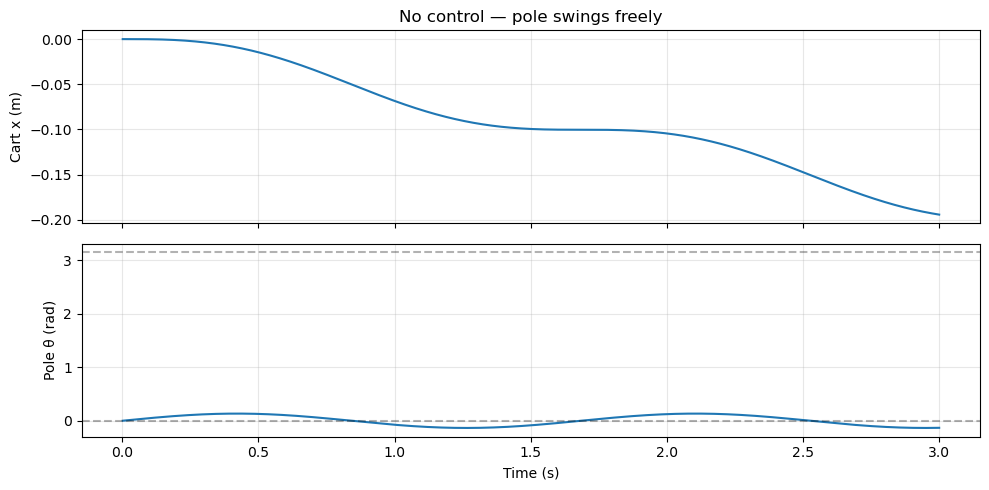

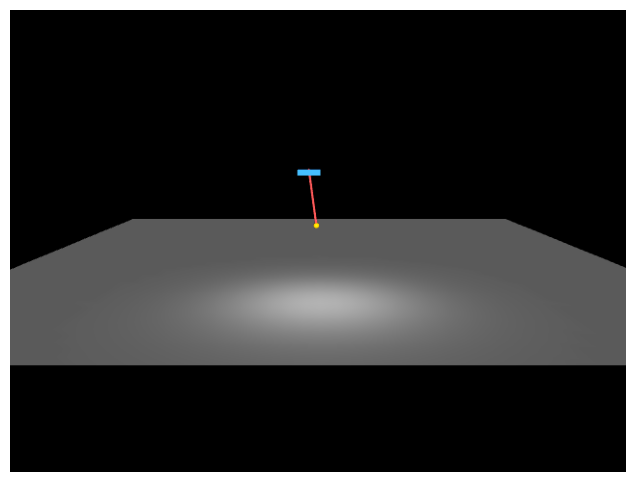

In [2]:
mujoco.mj_resetData(model, data)
data.qpos[:] = [0, 0]   # 摆杆下垂
data.qvel[:] = [0.0, 0.5]

times, xs, thetas = [], [], []
for _ in range(1500):       # 3 秒
    mujoco.mj_step(model, data)
    times.append(data.time)
    xs.append(data.qpos[0])
    thetas.append(data.qpos[1])

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
axes[0].plot(times, xs); axes[0].set_ylabel("Cart x (m)"); axes[0].grid(alpha=0.3)
axes[1].plot(times, thetas); axes[1].set_ylabel("Pole θ (rad)")
axes[1].axhline(0, color='k', ls='--', alpha=0.3)
axes[1].axhline(np.pi, color='k', ls='--', alpha=0.3)
axes[1].set_xlabel("Time (s)"); axes[1].grid(alpha=0.3)
axes[0].set_title("No control — pole swings freely")
plt.tight_layout(); plt.show()

# renderer = mujoco.Renderer(model, height=480, width=640)

# # 用当前 data 的状态渲染
# renderer.update_scene(data, camera="side_view")
# img = renderer.render()
# renderer.close()

# plt.figure(figsize=(8, 6))
# plt.imshow(img)
# plt.axis("off")
# plt.title(f"Final state: t = {data.time:.2f}s,  θ = {data.qpos[1]:.3f} rad")
# plt.show()

renderer = mujoco.Renderer(model, height=480, width=640)

cam = mujoco.MjvCamera()
mujoco.mjv_defaultCamera(cam)

cam.type = mujoco.mjtCamera.mjCAMERA_TRACKING
cam.trackbodyid = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, "cart")
cam.distance = 10.0      # 距离
cam.azimuth = 90        # 从侧面看
cam.elevation = -10     # 略俯视

renderer.update_scene(data, camera=cam)
img = renderer.render()
renderer.close()

plt.figure(figsize=(8, 6))
plt.imshow(img); plt.axis("off"); plt.show()

In [66]:
# ---- 物理参数 ----
M_cart = model.body_mass[1]
m_pole = model.body_mass[2]
L = 1.0
g = 9.81

# ---- 在"竖直向上 = 0"的坐标系下线性化 ----
# 用 φ = θ − π 作为角度误差
A = np.array([
    [0, 1, 0, 0],
    [0, 0,  -m_pole*g/M_cart, 0],              # ← 符号 +
    [0, 0, 0, 1],
    [0, 0, +(M_cart+m_pole)*g/(M_cart*L), 0], # ← 符号 −
])

B = np.array([
    [0],
    [1/M_cart],
    [0],
    [-1/(M_cart*L)],
])

Q = np.diag([1.0, 1.0, 500.0, 500.0])
R = np.array([[0.0001]])

P = solve_continuous_are(A, B, Q, R)
K = np.linalg.inv(R) @ B.T @ P

print("LQR gain K:", K)

poles = np.linalg.eigvals(A)
print("Poles:", poles)
print("All stable?", np.all(poles.real < 0))

poles = np.linalg.eigvals(A - B @ K)
print("Poles:", poles)
print("All stable?", np.all(poles.real < 0))

LQR gain K: [[ -100.          -318.74513428 -4589.17734354 -2573.0358958 ]]
Poles: [ 0.          0.          3.46902093 -3.46902093]
All stable? False
Poles: [-279.82901477+0.j           -0.47832802+0.45729751j
   -0.47832802-0.45729751j   -1.00067438+0.j        ]
All stable? True


In [88]:
class CartPoleController:
    def __init__(self, K, k_energy=5.0):
        self.K = K
        self.k_energy = k_energy
        self.balancing = False
        self.ON_THETA     = 0.2
        self.ON_THETA_DOT = 2.0
        self.OFF_THETA    = 0.3
        self.m = m_pole
        self.L = L
        self.g = g

    def __call__(self, state):
        x, x_dot, theta, theta_dot = state

        # 相对竖直向上（π）的角度误差
        phi = theta - np.pi

        # 切换逻辑用 phi
        if not self.balancing:
            if abs(phi) < self.ON_THETA and abs(theta_dot) < self.ON_THETA_DOT:
                self.balancing = True
        else:
            if abs(phi) > self.OFF_THETA:
                self.balancing = False

        if self.balancing:
            # LQR：用 phi 而不是 theta
            state_err = np.array([x, x_dot, phi, theta_dot])
            F = float(-self.K @ state_err)
        else:
            # 能量控制：目标能量是 θ = π 时的势能
            # 以 θ = 0 为零势能点
            E = 0.5 * self.m * self.L**2 * theta_dot**2 \
                + self.m * self.g * self.L * (1-np.cos(theta))  # ← 1-cos(θ)
            E_error = E - 2 * self.m * self.g * self.L
            E_error_clipped = np.clip(E_error, -35, 0)   # ← 限制但不缩太多
            F = -self.k_energy * E_error_clipped * theta_dot * np.cos(theta)
            # F = -self.k_energy * E_error * theta_dot * np.sin(theta)
            # F = -self.k_energy * np.sign(E_error) * theta_dot * np.sin(theta)


        return float(np.clip(F, -20, 20))



In [72]:
import mujoco
import numpy as np

controller = CartPoleController(K, k_energy=5.0)
def test_lqr_from(phi0):
    mujoco.mj_resetData(model, data)
    data.qpos[:] = [0, np.pi - phi0]
    data.qvel[:] = 0
    controller.balancing = True

    for _ in range(3000):
        state = np.array([data.qpos[0], data.qvel[0],
                          data.qpos[1], data.qvel[1]])
        data.ctrl[:] = controller(state)
        mujoco.mj_step(model, data)

    return data.qpos[1]

print("phi0   →  θ_final   stable?")
print("-" * 40)
for phi0 in [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.7, 1.0, 1.5]:
    theta_final = test_lqr_from(phi0)
    stable = abs(theta_final - np.pi) < 0.1
    print(f"{phi0:.2f}   →  {theta_final:.4f}   {'✅' if stable else '❌'}")

phi0   →  θ_final   stable?
----------------------------------------
0.05   →  3.1391   ✅
0.10   →  3.1362   ✅
0.20   →  3.1176   ✅
0.30   →  -2.1146   ❌
0.40   →  0.6844   ❌


/var/folders/k_/xy8dfwq124n1xv5xhkr0wz7m0000gn/T/ipykernel_3139/3797502385.py:30: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  F = float(-self.K @ state_err)


0.50   →  2.2260   ❌
0.70   →  2.1007   ❌
1.00   →  -1.6536   ❌
1.50   →  0.6888   ❌


/var/folders/k_/xy8dfwq124n1xv5xhkr0wz7m0000gn/T/ipykernel_3139/1339642585.py:30: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  F = float(-self.K @ state_err)


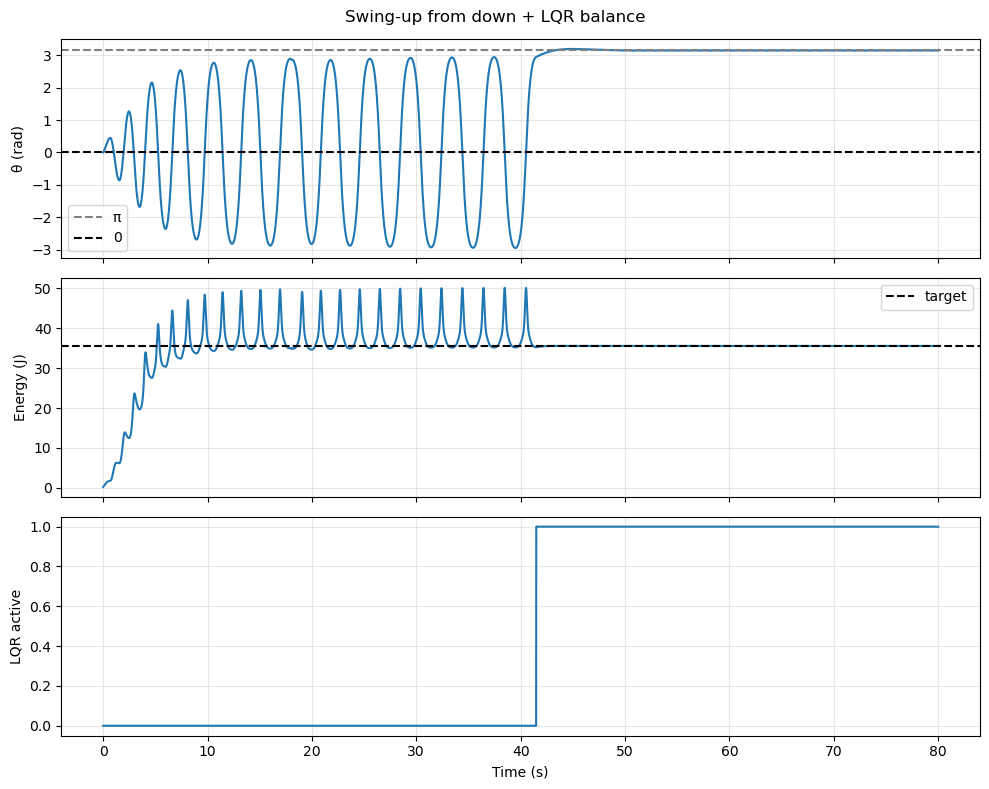

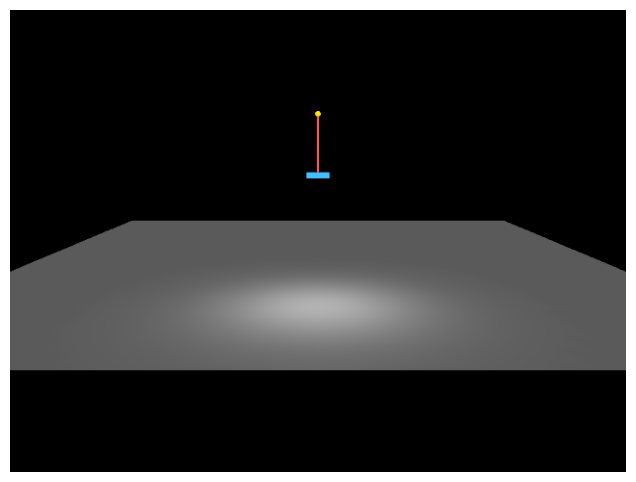

In [92]:
mujoco.mj_resetData(model, data)
data.qpos[:] = [0, 0.0]
data.qvel[:] = [0.0, 0.5]
controller = CartPoleController(K, k_energy=5.0)
controller.balancing = False

controller.ON_THETA     = 0.2
controller.ON_THETA_DOT = 0.8
controller.OFF_THETA    = 0.3

times, thetas, energies, modes = [], [], [], []   # ← 加 times
for i in range(40000):
    state = np.array([data.qpos[0], data.qvel[0],
                      data.qpos[1], data.qvel[1]])
    data.ctrl[:] = controller(state)
    mujoco.mj_step(model, data)

    times.append(data.time)                        # ← 记录时间
    thetas.append(data.qpos[1])
    E = 0.5*m_pole*L**2*data.qvel[1]**2 + m_pole*g*L*(1-np.cos(data.qpos[1]))
    energies.append(E)
    modes.append(controller.balancing)

# 画图 —— x 轴用 times
fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
axes[0].plot(times, thetas)                        # ← times
axes[0].axhline(np.pi, color='gray', ls='--', label='π')
axes[0].axhline(0, color='k', ls='--', label='0')
axes[0].set_ylabel("θ (rad)")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(times, energies)                      # ← times
axes[1].axhline(2*m_pole*g*L, color='k', ls='--', label='target')
axes[1].set_ylabel("Energy (J)")
axes[1].legend(); axes[1].grid(alpha=0.3)

axes[2].plot(times, modes)                         # ← times
axes[2].set_ylabel("LQR active")
axes[2].set_xlabel("Time (s)")                     # ← 改成秒
axes[2].grid(alpha=0.3)

plt.suptitle("Swing-up from down + LQR balance")
plt.tight_layout()
plt.show()


renderer = mujoco.Renderer(model, height=480, width=640)

cam = mujoco.MjvCamera()
mujoco.mjv_defaultCamera(cam)

cam.type = mujoco.mjtCamera.mjCAMERA_TRACKING
cam.trackbodyid = mujoco.mj_name2id(model, mujoco.mjtObj.mjOBJ_BODY, "cart")
cam.distance = 10.0      # 距离
cam.azimuth = 90        # 从侧面看
cam.elevation = -10     # 略俯视

renderer.update_scene(data, camera=cam)
img = renderer.render()
renderer.close()

plt.figure(figsize=(8, 6))
plt.imshow(img); plt.axis("off"); plt.show()